# Hebbian Learning

Hebbian learning is one of the oldest ideas in learning systems:

> When an input and an output unit are active at the same time, the connection between them is
> strengthened.

In a linear unit with input $x$ and output $y = w^\top x$, the simplest Hebb rule is

$$
\Delta w = \eta\, y\, x.
$$

This notebook treats Hebbian learning as **unsupervised representation learning**, not as a neural
network training recipe. We will see that:

- the raw Hebb rule is unstable because weights grow without bound;
- normalising the weight vector turns Hebbian learning into a principal-component learner;
- Oja's rule stabilises the same idea and converges to the first principal component;
- a Hebbian outer-product memory can store and recall patterns.

## Learning objectives

By the end of this notebook you can:

- state the basic Hebbian update and explain its intuition;
- explain why raw Hebbian learning diverges;
- implement normalised Hebbian learning and Oja's rule;
- compare the learned direction with the first principal component;
- build a simple Hebbian associative memory.

## 1. The basic Hebb rule

For a linear unit,

$$
y = w^\top x,
\qquad
\Delta w = \eta\, y\, x.
$$

If $x$ is repeatedly aligned with $w$, the weight vector grows in that direction. There is no
built-in limit, so the norm of $w$ can increase without bound. The **direction** may become useful
even while the **scale** explodes.

### Normalised Hebb rule

A simple fix is to renormalise after each update:

$$
w \leftarrow \frac{w + \eta\, y\, x}{\lVert w + \eta\, y\, x\rVert}.
$$

This is a stochastic power iteration. For zero-mean data, it converges to the direction of largest
variance, i.e. the first principal component.

### Oja's rule

Oja's rule adds a decay term that keeps the norm under control:

$$
\Delta w = \eta\, y\,(x - y\,w).
$$

The term $-y w$ subtracts a component proportional to the current weight, so the rule self-normalises
and converges to the first principal component.

### What Hebbian learning is not

- It is not supervised: no labels are used.
- It is not a classifier by itself.
- It learns correlations, not causal effects.
- In its basic form it is unstable; normalisation or a decay term is essential.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## 2. Create correlated two-dimensional data

We generate a cloud stretched along one direction. The first principal component is the direction
of maximum variance. A successful Hebbian learner should find that direction without using labels.

In [2]:
mean = np.array([0.0, 0.0])
covariance = np.array([[3.0, 2.0], [2.0, 2.0]])
X = rng.multivariate_normal(mean, covariance, size=500)
X = X - X.mean(axis=0)

cov_empirical = np.cov(X.T)
eigenvalues, eigenvectors = np.linalg.eigh(cov_empirical)
pc1 = eigenvectors[:, np.argmax(eigenvalues)]
pc1 = pc1 / np.linalg.norm(pc1)

print("Empirical covariance:")
print(cov_empirical.round(3))
print("Eigenvalues:", eigenvalues.round(3))
print("First principal component:", pc1.round(3))

Empirical covariance:
[[3.148 1.919]
 [1.919 1.766]]
Eigenvalues: [0.417 4.496]
First principal component: [-0.818 -0.575]


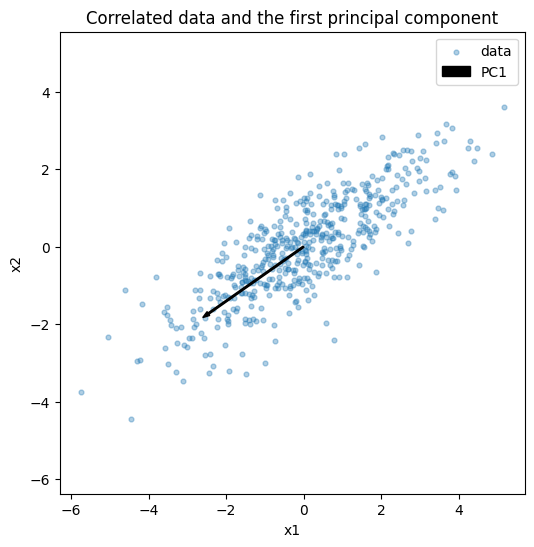

In [3]:
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=12, alpha=0.35, label="data")
scale = 3.0
plt.arrow(0, 0, scale * pc1[0], scale * pc1[1], color="black", width=0.04, label="PC1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Correlated data and the first principal component")
plt.axis("equal")
plt.legend()
plt.show()

## 3. Helper functions

We track two quantities over training:

- the angle between the current weight vector and PC1 (using the absolute cosine because the sign
  of an eigenvector is arbitrary);
- the norm of the weight vector.

In [4]:
def angle_to_pc1(w, reference=pc1):
    cosine = np.dot(w, reference) / (np.linalg.norm(w) * np.linalg.norm(reference))
    cosine = np.clip(abs(cosine), -1.0, 1.0)
    return np.degrees(np.arccos(cosine))


def train_raw_hebb(X, eta=1e-3, epochs=5, seed=0):
    local_rng = np.random.default_rng(seed)
    w = local_rng.normal(size=X.shape[1])
    w = w / np.linalg.norm(w)
    history = []

    for epoch in range(epochs):
        for x in X:
            y = np.dot(w, x)
            w = w + eta * y * x
        history.append(
            {
                "epoch": epoch + 1,
                "angle": angle_to_pc1(w),
                "norm": np.linalg.norm(w),
                "w1": w[0],
                "w2": w[1],
            }
        )

    return w, pd.DataFrame(history)


def train_normalized_hebb(X, eta=0.01, epochs=20, seed=0):
    local_rng = np.random.default_rng(seed)
    w = local_rng.normal(size=X.shape[1])
    w = w / np.linalg.norm(w)
    history = []

    for epoch in range(epochs):
        for x in X:
            y = np.dot(w, x)
            w = w + eta * y * x
            w = w / np.linalg.norm(w)
        history.append(
            {
                "epoch": epoch + 1,
                "angle": angle_to_pc1(w),
                "norm": np.linalg.norm(w),
                "w1": w[0],
                "w2": w[1],
            }
        )

    return w, pd.DataFrame(history)


def train_oja(X, eta=0.01, epochs=20, seed=0):
    local_rng = np.random.default_rng(seed)
    w = local_rng.normal(size=X.shape[1])
    w = w / np.linalg.norm(w)
    history = []

    for epoch in range(epochs):
        for x in X:
            y = np.dot(w, x)
            w = w + eta * y * (x - y * w)
        history.append(
            {
                "epoch": epoch + 1,
                "angle": angle_to_pc1(w),
                "norm": np.linalg.norm(w),
                "w1": w[0],
                "w2": w[1],
            }
        )

    return w, pd.DataFrame(history)

## 4. Raw Hebb: the direction improves, the scale explodes

In [5]:
w_raw, raw_history = train_raw_hebb(X, eta=1e-3, epochs=5)

print("Final raw Hebb weight:", w_raw.round(3))
print("Final raw Hebb norm:", round(np.linalg.norm(w_raw), 3))
print("Final angle to PC1:", round(raw_history["angle"].iloc[-1], 3), "degrees")
raw_history.round(3)

Final raw Hebb weight: [8124.51  5654.354]
Final raw Hebb norm: 9898.453
Final angle to PC1: 0.257 degrees


,epoch,angle,norm,w1,w2
0,1,42.431,1.811,1.796,-0.231
1,2,7.137,12.467,11.012,5.845
2,3,1.160,114.836,95.278,64.105
3,4,0.363,1066.039,876.111,607.345
4,5,0.257,9898.453,8124.510,5654.354


The angle may shrink toward PC1, but the norm grows rapidly. The model has no stable scale, so the
raw rule cannot be used as-is.

## 5. Normalised Hebb converges to PC1

In [6]:
w_norm, norm_history = train_normalized_hebb(X, eta=0.01, epochs=20)

print("Final normalised Hebb weight:", w_norm.round(3))
print("Final normalised Hebb norm:", round(np.linalg.norm(w_norm), 3))
print("Final angle to PC1:", round(norm_history["angle"].iloc[-1], 3), "degrees")
norm_history.tail().round(3)

Final normalised Hebb weight: [0.817 0.577]
Final normalised Hebb norm: 1.0
Final angle to PC1: 0.154 degrees


,epoch,angle,norm,w1,w2
15,16,0.154,1.0,0.817,0.577
16,17,0.154,1.0,0.817,0.577
17,18,0.154,1.0,0.817,0.577
18,19,0.154,1.0,0.817,0.577
19,20,0.154,1.0,0.817,0.577


## 6. Oja's rule also converges and keeps its norm stable

In [7]:
w_oja, oja_history = train_oja(X, eta=0.01, epochs=20)

print("Final Oja weight:", w_oja.round(3))
print("Final Oja norm:", round(np.linalg.norm(w_oja), 3))
print("Final angle to PC1:", round(oja_history["angle"].iloc[-1], 3), "degrees")
oja_history.tail().round(3)

Final Oja weight: [0.821 0.573]
Final Oja norm: 1.001
Final angle to PC1: 0.191 degrees


,epoch,angle,norm,w1,w2
15,16,0.191,1.001,0.821,0.573
16,17,0.191,1.001,0.821,0.573
17,18,0.191,1.001,0.821,0.573
18,19,0.191,1.001,0.821,0.573
19,20,0.191,1.001,0.821,0.573


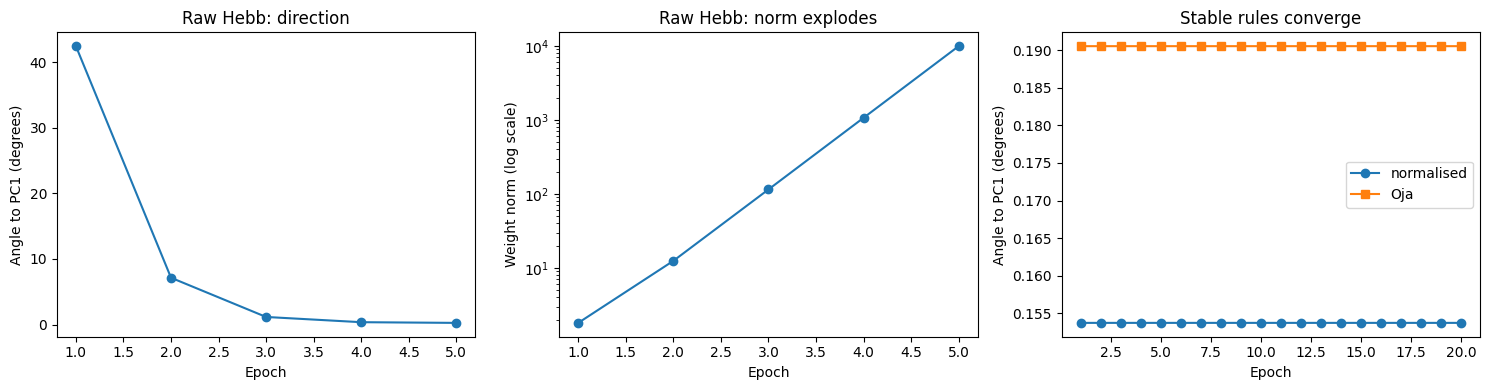

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(raw_history["epoch"], raw_history["angle"], marker="o")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Angle to PC1 (degrees)")
axes[0].set_title("Raw Hebb: direction")

axes[1].plot(raw_history["epoch"], raw_history["norm"], marker="o")
axes[1].set_yscale("log")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Weight norm (log scale)")
axes[1].set_title("Raw Hebb: norm explodes")

axes[2].plot(norm_history["epoch"], norm_history["angle"], marker="o", label="normalised")
axes[2].plot(oja_history["epoch"], oja_history["angle"], marker="s", label="Oja")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Angle to PC1 (degrees)")
axes[2].set_title("Stable rules converge")
axes[2].legend()

plt.tight_layout()
plt.show()

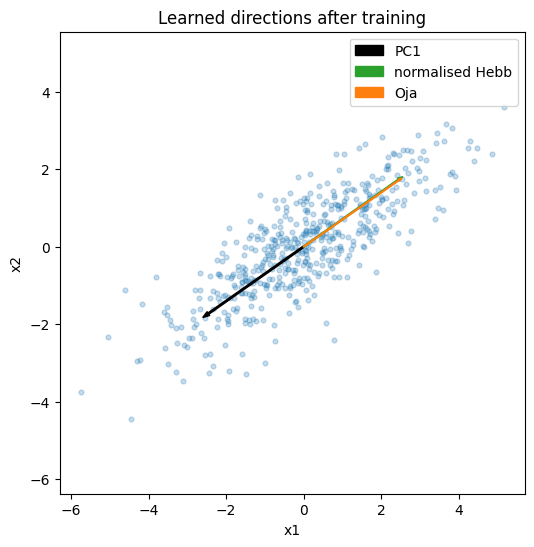

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(X[:, 0], X[:, 1], s=12, alpha=0.25)
ax.arrow(0, 0, 3 * pc1[0], 3 * pc1[1], color="black", width=0.04, label="PC1")
ax.arrow(0, 0, 3 * w_norm[0], 3 * w_norm[1], color="tab:green", width=0.03, label="normalised Hebb")
ax.arrow(0, 0, 3 * w_oja[0], 3 * w_oja[1], color="tab:orange", width=0.02, label="Oja")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("Learned directions after training")
ax.axis("equal")
ax.legend()
plt.show()

Both stable rules recover essentially the same direction as PC1. The sign may differ: $w$ and $-w$
represent the same axis. This is why we use the absolute cosine when measuring the angle.

## 7. A Hebbian associative memory

The outer-product rule stores associations between input patterns and output patterns:

$$
W = \sum_{p} y^{(p)} (x^{(p)})^\top.
$$

For auto-associative memory, $y^{(p)} = x^{(p)}$ and $W = \sum_p x^{(p)}(x^{(p)})^\top$. A cue $c$
is recalled by

$$
\hat{x} = \operatorname{sign}(Wc).
$$

If the stored patterns are orthogonal, they can be recovered from small amounts of noise. We use
four rows of a $16\times16$ Hadamard matrix, which gives four mutually orthogonal 16-bit patterns.

In [10]:
def hadamard_matrix(size):
    H = np.array([[1]])
    while H.shape[0] < size:
        H = np.block([[H, H], [H, -H]])
    return H


patterns = hadamard_matrix(16)[1:5]
gram = patterns @ patterns.T
off_diagonal = gram - np.diag(np.diag(gram))

print("Pattern norms:", np.diag(gram))
print("Maximum absolute off-diagonal overlap:", np.max(np.abs(off_diagonal)))
print("Pattern matrix shape:", patterns.shape)

memory = patterns.T @ patterns
print("Memory matrix shape:", memory.shape)

Pattern norms: [16 16 16 16]
Maximum absolute off-diagonal overlap: 0
Pattern matrix shape: (4, 16)
Memory matrix shape: (16, 16)


In [11]:
def recall(cue):
    activations = memory @ cue
    return np.where(activations >= 0, 1, -1)


noise_levels = [0, 1, 2, 3, 4]
accuracy_rows = []

for n_flips in noise_levels:
    successes = 0
    trials = 200
    for _ in range(trials):
        target = patterns[rng.integers(len(patterns))]
        cue = target.copy()
        if n_flips:
            flip_indices = rng.choice(len(target), size=n_flips, replace=False)
            cue[flip_indices] *= -1
        successes += int(np.array_equal(recall(cue), target))
    accuracy_rows.append({"flipped_bits": n_flips, "accuracy": successes / trials})

memory_accuracy = pd.DataFrame(accuracy_rows).set_index("flipped_bits")
memory_accuracy.round(3)

,accuracy
flipped_bits,
0,1.000
1,1.000
2,0.925
3,0.725
4,0.430


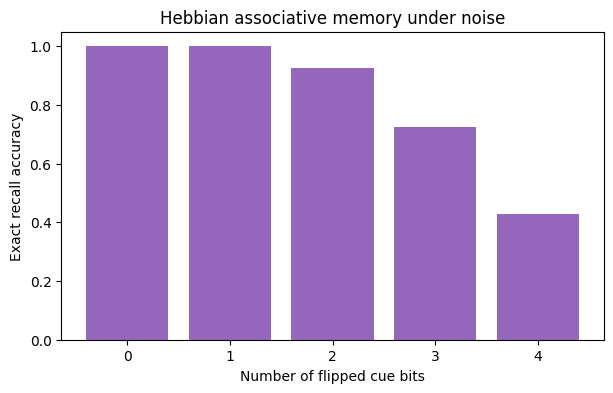

In [12]:
plt.figure(figsize=(7, 4))
plt.bar(memory_accuracy.index.astype(str), memory_accuracy["accuracy"], color="tab:purple")
plt.xlabel("Number of flipped cue bits")
plt.ylabel("Exact recall accuracy")
plt.title("Hebbian associative memory under noise")
plt.ylim(0, 1.05)
plt.show()

The memory tolerates a few flipped bits because the stored patterns are orthogonal. With correlated
patterns, cross-talk between memories reduces capacity. This is the same trade-off between
compression and interference that appears in many representation-learning systems.

## 8. What Hebbian learning teaches us

- Learning can be driven by correlations rather than labels.
- A simple local update can discover the dominant direction of variation.
- Stability requires a normalisation or decay mechanism.
- Hebbian ideas connect to PCA, independent component analysis, competitive learning, and
  associative memory.
- The basic rule is not a full learning algorithm: it needs a stability constraint, a stopping
  rule, and an evaluation criterion.

## Summary

| Rule | Update | Behaviour |
| --- | --- | --- |
| Raw Hebb | $\Delta w = \eta y x$ | Direction can improve, norm diverges |
| Normalised Hebb | Raw update, then $w \leftarrow w/\lVert w\rVert$ | Converges to PC1 |
| Oja | $\Delta w = \eta y(x-yw)$ | Converges to PC1 with stable norm |
| Outer-product memory | $W=\sum yx^\top$ | Stores and recalls patterns |

## Exercises

1. Change the covariance matrix so the first two eigenvalues are nearly equal. Does the learned
   direction become unstable?
2. Run normalised Hebb with a very large learning rate. What happens to the angle trajectory?
3. Implement a decaying learning rate for Oja's rule and compare convergence.
4. Store six orthogonal patterns from the Hadamard matrix and measure recall accuracy under noise.
5. Store two highly correlated patterns and explain the cross-talk you observe.
6. Connect the normalised Hebb update to the power-iteration algorithm from linear algebra.